# LAB 1 for CS4243: Textures and Materials
## Notebook 2 — Material classification and defect localisation

> **Introduction.** This notebook runs Tasks A and B on real MVTec data. For
> Task B, normal models are fitted on training images, the pixel threshold is
> selected on public validation masks, and final results are reported on the
> held-out test split. Never tune a parameter after viewing test results.


## 1. Imports and reproducible configuration

Images are resized for a responsive walkthrough. Set `MAX_PER_GROUP = None`
when running the final experiment on every validation and test image.


In [49]:
import sys
from collections import Counter
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

from texturelab.config import FeatureConfig, GaborConfig, NormalityConfig
from texturelab.data import load_mask, read_manifest
from texturelab.evaluation import evaluate_detection, evaluate_material
from texturelab.features import extract_local_features, global_pool
from texturelab.models import fit_material_classifier
from texturelab.normality import (
    fit_normal_model,
    predict_anomaly,
    select_mask_threshold,
)
from texturelab.supplied import load_image
from texturelab.visualize import plot_confusion, plot_reliability

MATERIALS = ("carpet", "grid", "leather", "tile", "wood")
IMAGE_SIZE = (64, 64)
MAX_PER_GROUP = None # Use None for the complete final evaluation.

feature_config = FeatureConfig(
    gabor=GaborConfig(
        frequencies=(0.10, 0.22),
        orientations=(0, np.pi / 2),
        kernel_size=11,
        pool_size=7,
    )
)
normal_config = NormalityConfig(
    image_percentile=99,
    threshold_percentile=99.5,
    score_pool_size=7,
    ignore_border=5,
)
mvtec = read_manifest(ROOT / "manifests" / "mvtec_textures.csv")

## 2. Audit the new split

The original labelled MVTec set is split deterministically within every
material/defect group: even-numbered files form validation and odd-numbered
files form test. This keeps every defect type in both partitions.


Counter({'train': 1266, 'validation': 267, 'test': 248})


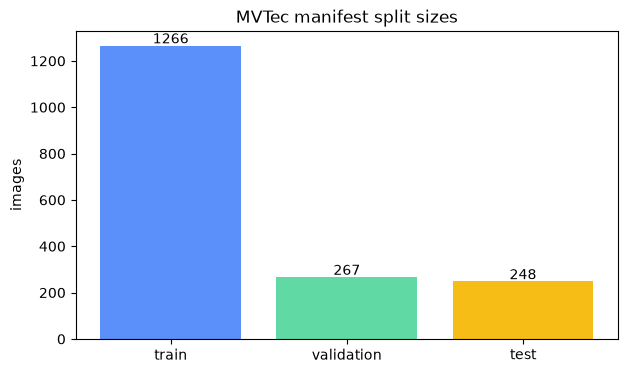

In [50]:
split_counts = Counter(record.split for record in mvtec)
print(split_counts)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(split_counts.keys(), split_counts.values(), color=["#5b8ff9", "#61d9a5", "#f6bd16"])
ax.set(title="MVTec manifest split sizes", ylabel="images")
for index, value in enumerate(split_counts.values()):
    ax.text(index, value + 10, str(value), ha="center")
plt.show()

## 3. Task A — material classification

Task A uses only normal training images for fitting. The validation and test
sets below contain one good and one defective example per material so that the
walkthrough remains quick; use the complete sets for final reporting.


In [51]:
def first_records(split, material, condition, count=None):
    # Select all matching records, or the first count if specified.
    selected = [
        record
        for record in mvtec
        if record.split == split
        and record.material == material
        and (
            (condition == "good" and record.defect_type == "good")
            or (condition == "defective" and record.defect_type != "good")
        )
    ]
    return selected if count is None else selected[:count]


train_records = sum(
    ([r for r in mvtec if r.split == "train" and r.material == material]
     for material in MATERIALS),
    [],
)
validation_records = sum(
    (first_records("validation", material, "good")
     + first_records("validation", material, "defective")
     for material in MATERIALS),
    [],
)
test_records = sum(
    (first_records("test", material, "good")
     + first_records("test", material, "defective")
     for material in MATERIALS),
    [],
)


def image_descriptor(record, config=feature_config):
    image = load_image(record.path, IMAGE_SIZE)
    feature_map, _ = extract_local_features(image, config)
    return global_pool(feature_map)


x_train = np.stack([image_descriptor(record) for record in train_records])
x_validation = np.stack([image_descriptor(record) for record in validation_records])
x_test = np.stack([image_descriptor(record) for record in test_records])

material_model = fit_material_classifier(
    x_train,
    [record.material for record in train_records],
    C=5.0,
)

### Visualise descriptor separation and test performance

PCA is used only for visualisation. The classifier itself receives the full
descriptor through a `StandardScaler` + `LogisticRegression` pipeline.


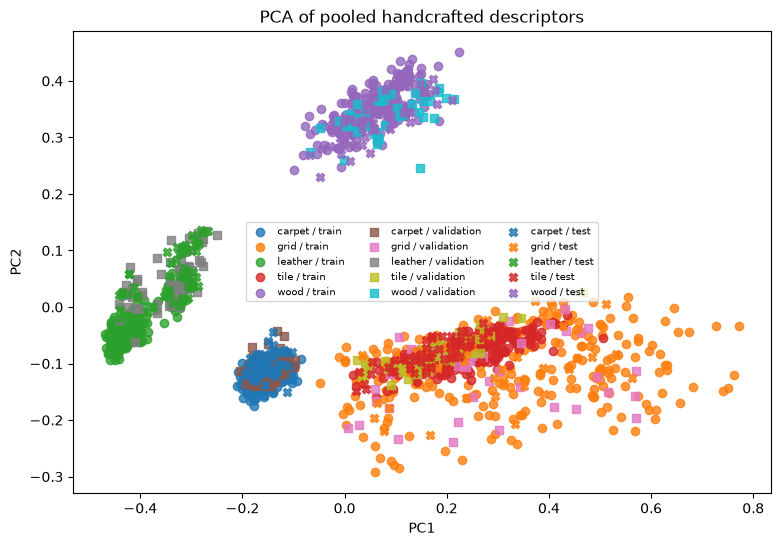

{'overall': {'count': 248, 'accuracy': 1.0, 'macro_f1': 1.0, 'confusion_matrix': [[56, 0, 0, 0, 0], [0, 37, 0, 0, 0], [0, 0, 60, 0, 0], [0, 0, 0, 57, 0], [0, 0, 0, 0, 38]], 'ece': 0.006530848962645377}, 'good': {'count': 65, 'accuracy': 1.0, 'macro_f1': 1.0, 'confusion_matrix': [[14, 0, 0, 0, 0], [0, 10, 0, 0, 0], [0, 0, 16, 0, 0], [0, 0, 0, 16, 0], [0, 0, 0, 0, 9]], 'ece': 0.006557678259336031}, 'defective': {'count': 183, 'accuracy': 1.0, 'macro_f1': 1.0, 'confusion_matrix': [[42, 0, 0, 0, 0], [0, 27, 0, 0, 0], [0, 0, 44, 0, 0], [0, 0, 0, 41, 0], [0, 0, 0, 0, 29]], 'ece': 0.006521193056158681}}


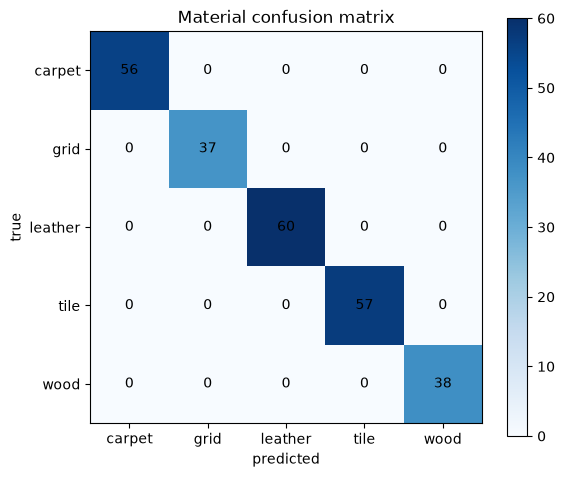

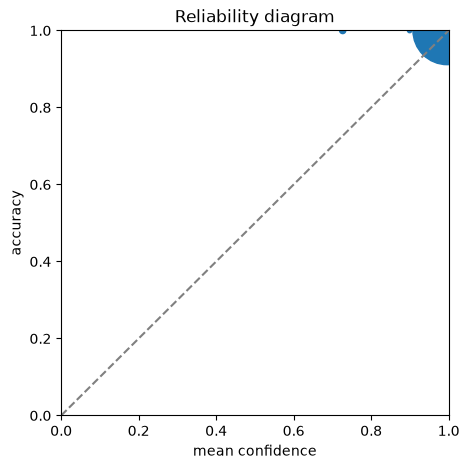

In [52]:
all_descriptors = np.vstack([x_train, x_validation, x_test])
projection = PCA(n_components=2).fit_transform(all_descriptors)
groups = (
    [(record, "train") for record in train_records]
    + [(record, "validation") for record in validation_records]
    + [(record, "test") for record in test_records]
)

fig, ax = plt.subplots(figsize=(9, 6))
markers = {"train": "o", "validation": "s", "test": "X"}
for split in markers:
    for material in MATERIALS:
        chosen = np.array(
            [record.material == material and group_split == split
             for record, group_split in groups]
        )
        ax.scatter(
            projection[chosen, 0],
            projection[chosen, 1],
            marker=markers[split],
            label=f"{material} / {split}",
            alpha=0.8,
        )
ax.set(title="PCA of pooled handcrafted descriptors", xlabel="PC1", ylabel="PC2")
ax.legend(ncol=3, fontsize=7)
plt.show()

test_probabilities = material_model.predict_proba(x_test)
task_a_report = evaluate_material(
    [record.material for record in test_records],
    test_probabilities,
    material_model.classes_,
    ["good" if record.defect_type == "good" else "defective"
     for record in test_records],
)
print(task_a_report)
plot_confusion(
    np.asarray(task_a_report["overall"]["confusion_matrix"]),
    material_model.classes_,
)
plot_reliability(
    np.asarray([record.material for record in test_records]),
    test_probabilities,
    material_model.classes_,
)
plt.show()

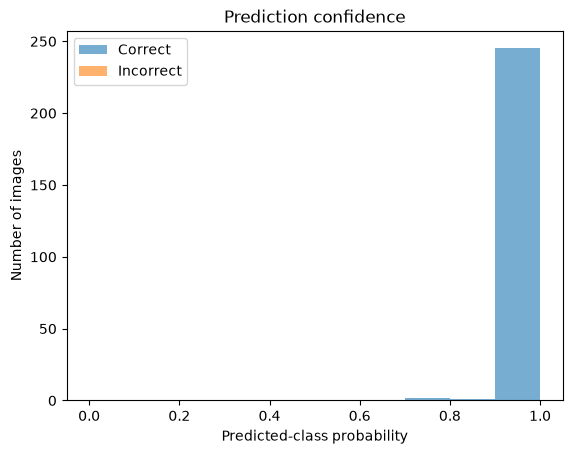

In [53]:
#generate histogram of confidence for correct and incorrect predictions
y_true = np.array([r.material for r in test_records])
y_pred = material_model.classes_[test_probabilities.argmax(axis=1)]
confidence = test_probabilities.max(axis=1)
correct = y_pred == y_true

bins = np.linspace(0, 1, 11)
plt.hist(confidence[correct], bins=bins, alpha=0.6, label="Correct")
plt.hist(confidence[~correct], bins=bins, alpha=0.6, label="Incorrect")
plt.xlabel("Predicted-class probability")
plt.ylabel("Number of images")
plt.title("Prediction confidence")
plt.legend()
plt.show()

In [54]:
# Predict materials for the validation descriptors.
validation_probabilities = material_model.predict_proba(x_validation)

validation_true = np.array([r.material for r in validation_records])
validation_pred = material_model.classes_[
    validation_probabilities.argmax(axis=1)
]
validation_confidence = validation_probabilities.max(axis=1)

wrong = np.flatnonzero(validation_pred != validation_true)
wrong = wrong[
    np.argsort(validation_confidence[wrong])[::-1]
]

print(f"{len(wrong)} errors out of {len(validation_true)} images")

for i in wrong:
    record = validation_records[i]
    print(
        f"index {i} | "
        f"{validation_true[i]} → {validation_pred[i]} | "
        f"confidence: {validation_confidence[i]:.2%} | "
        f"defect: {record.defect_type}\n"
        f"{record.path}\n"
    )

5 errors out of 267 images
index 243 | wood → tile | confidence: 99.17% | defect: combined
C:\Users\Matthew\Desktop\Y4S1\CS4243 Lab 1\data\MVTec\wood\test\combined\006.png

index 18 | carpet → tile | confidence: 93.94% | defect: color
C:\Users\Matthew\Desktop\Y4S1\CS4243 Lab 1\data\MVTec\carpet\test\color\008.png

index 101 | grid → tile | confidence: 75.24% | defect: thread
C:\Users\Matthew\Desktop\Y4S1\CS4243 Lab 1\data\MVTec\grid\test\thread\010.png

index 63 | grid → carpet | confidence: 68.30% | defect: good
C:\Users\Matthew\Desktop\Y4S1\CS4243 Lab 1\data\MVTec\grid\test\good\004.png

index 120 | leather → carpet | confidence: 54.05% | defect: color
C:\Users\Matthew\Desktop\Y4S1\CS4243 Lab 1\data\MVTec\leather\test\color\004.png



True: wood, predicted: tile, confidence: 99.17%
Source: C:\Users\Matthew\Desktop\Y4S1\CS4243 Lab 1\data\MVTec\wood\test\combined\006.png


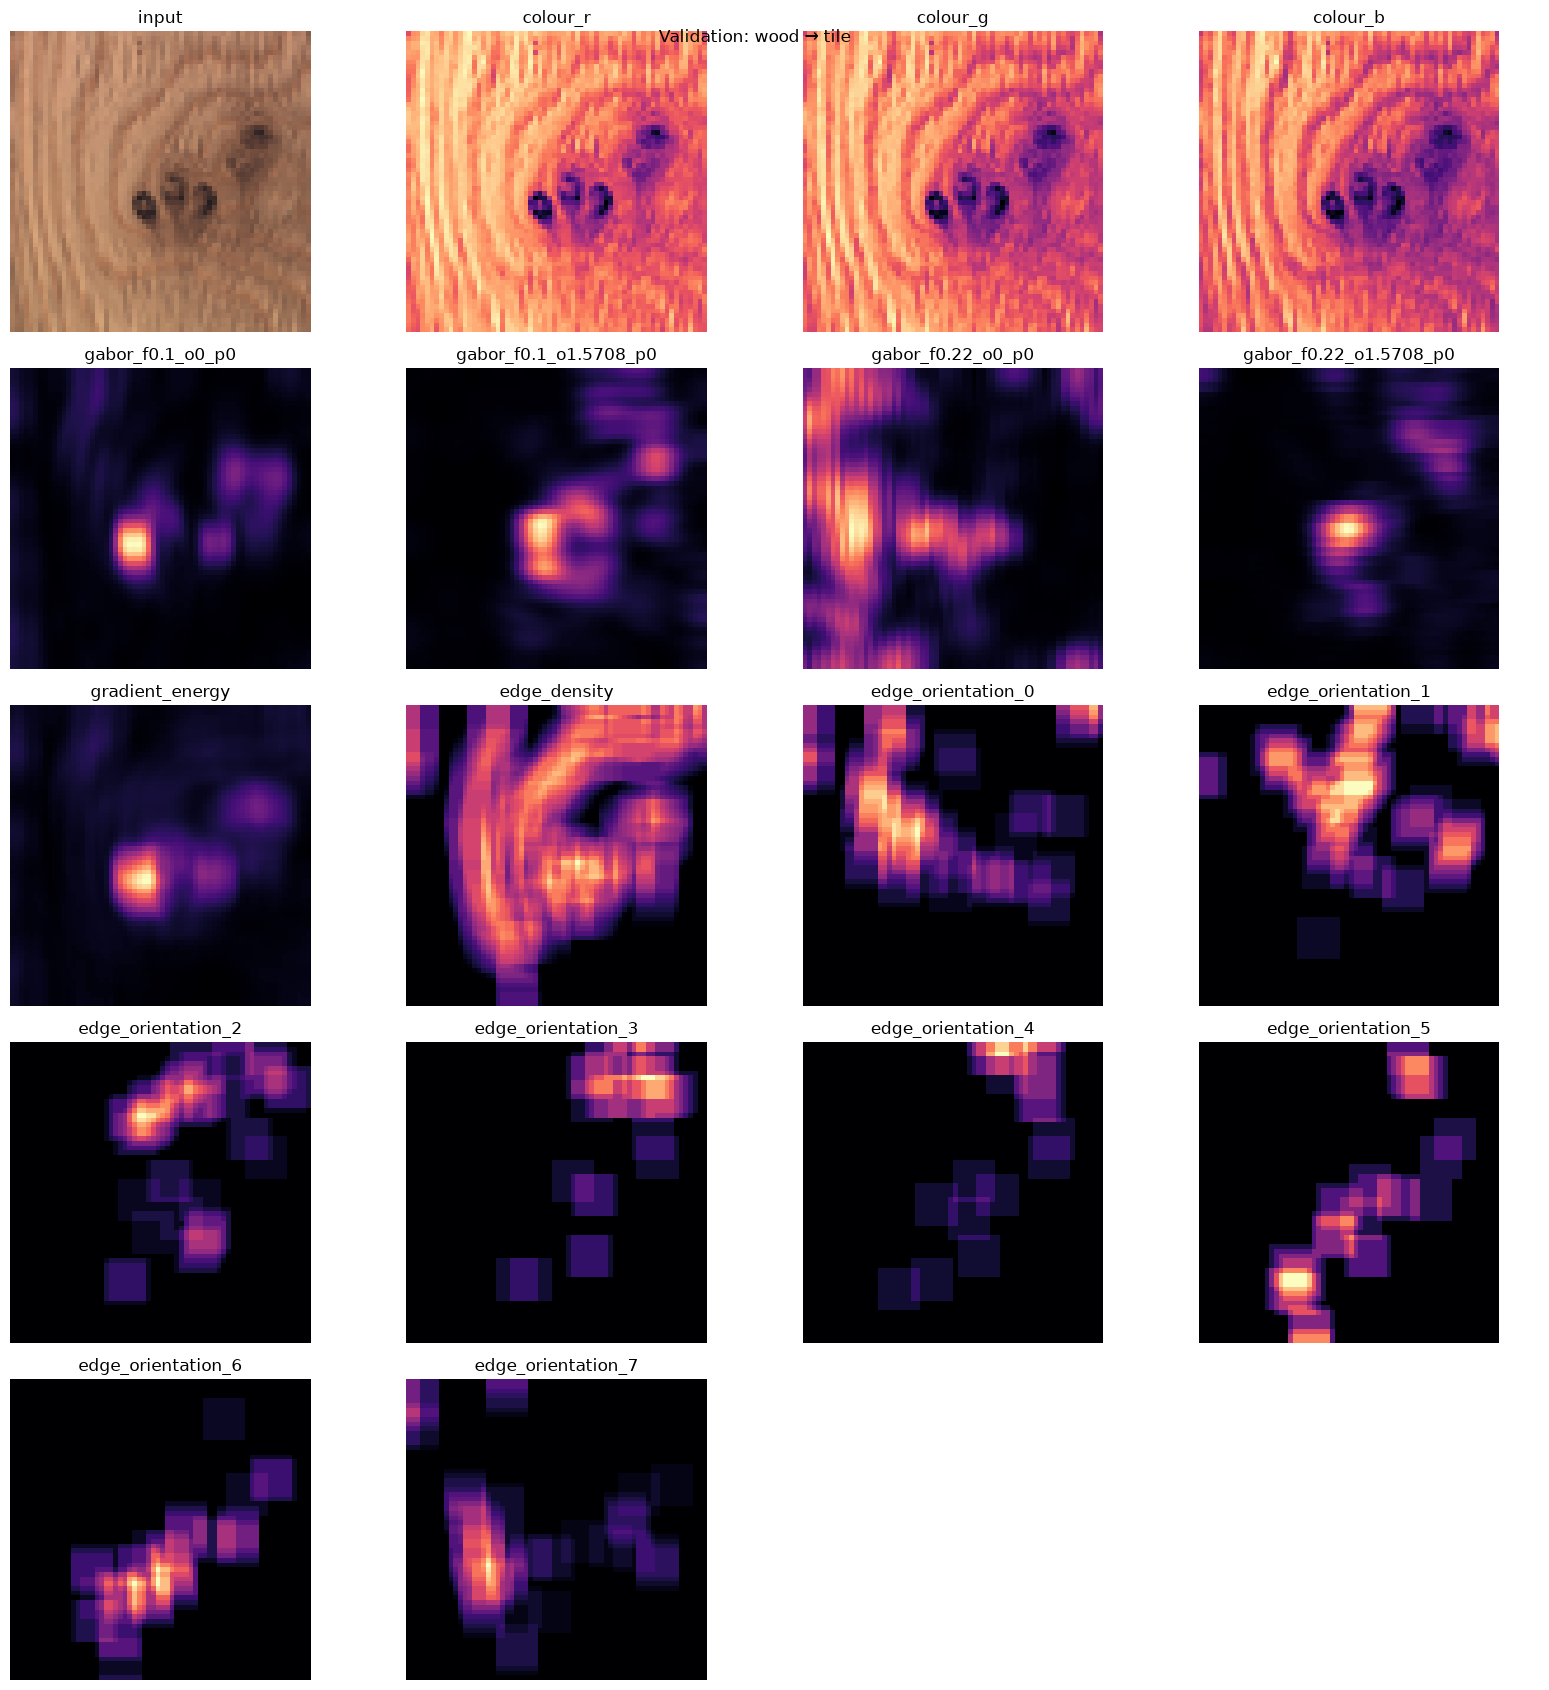

True: carpet, predicted: tile, confidence: 93.94%
Source: C:\Users\Matthew\Desktop\Y4S1\CS4243 Lab 1\data\MVTec\carpet\test\color\008.png


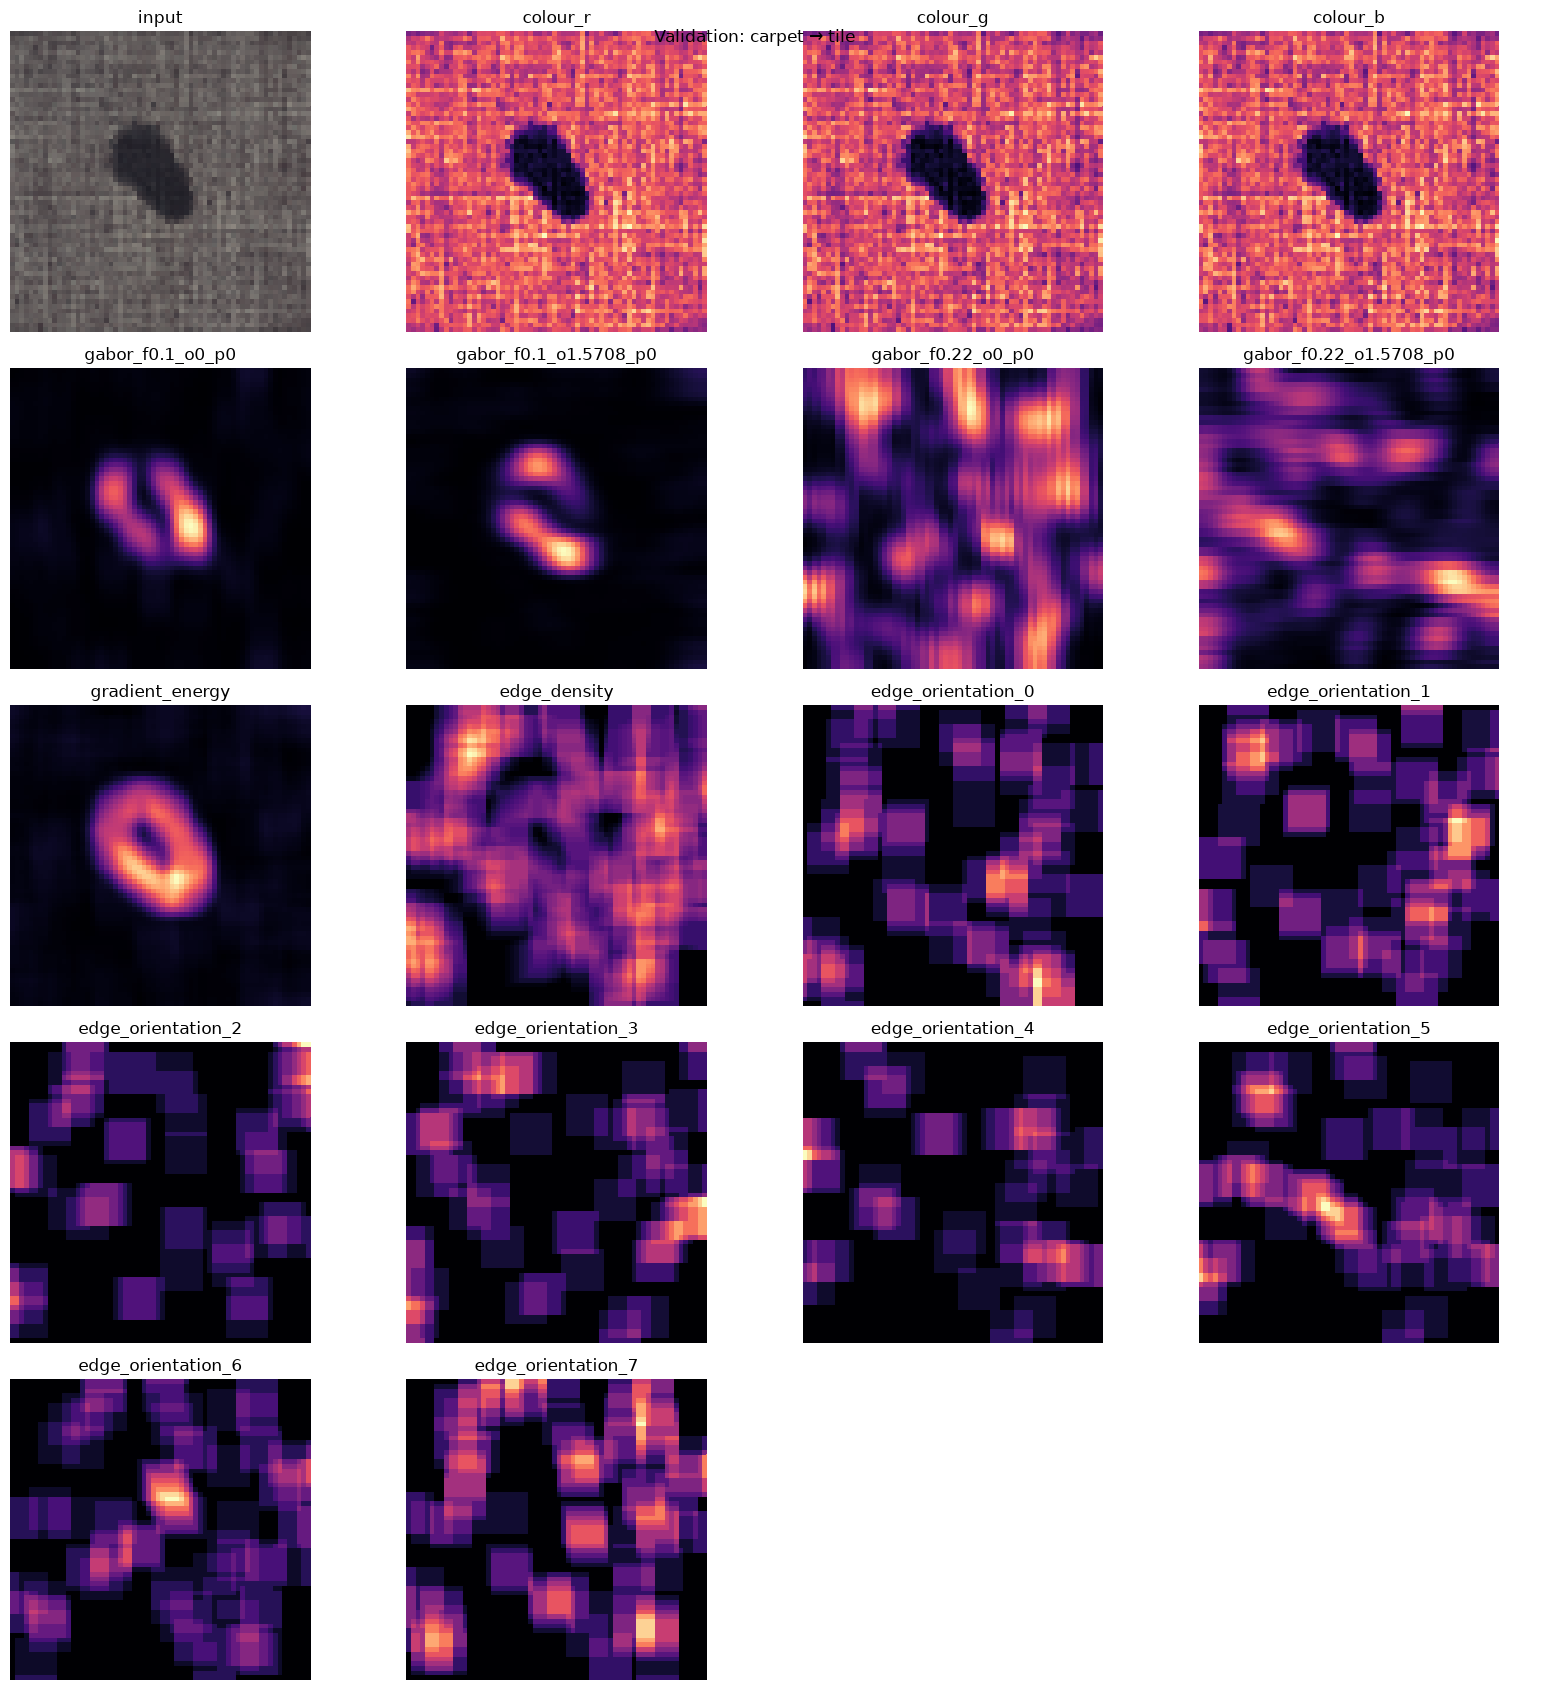

In [55]:
# Visualize the feature maps for the first two incorrect predictions. `[AI-CODE]` `[HUMAN-CHECK]`
from texturelab.visualize import show_feature_maps

for i in wrong[:2]:
    record = validation_records[i]

    image = load_image(record.path, IMAGE_SIZE)
    maps, names = extract_local_features(image, feature_config)

    print(
        f"True: {validation_true[i]}, "
        f"predicted: {validation_pred[i]}, "
        f"confidence: {validation_confidence[i]:.2%}\n"
        f"Source: {record.path}"
    )

    fig = show_feature_maps(
        image, maps, names,
        max_maps=len(names),
    )
    fig.suptitle(
        f"Validation: {validation_true[i]} → {validation_pred[i]}"
    )
    plt.show()

## 4. Task B — fit normal patch models

One model is fitted per material using normal training patches. Local averaging
of the standardized score suppresses isolated responses, and an outer border
is ignored because reflected filtering makes it unreliable.


In [56]:
normal_models = {}
for material in MATERIALS:
    records = [
        record
        for record in mvtec
        if record.split == "train" and record.material == material
    ]
    feature_maps = [
        extract_local_features(load_image(record.path, IMAGE_SIZE), feature_config)[0]
        for record in records
    ]
    normal_models[material] = fit_normal_model(feature_maps, normal_config)

## 5. Tune the mask threshold on validation only

This is the only stage allowed to inspect validation masks. The selected
threshold is copied into each material model and then frozen before test
evaluation.


In [57]:
def evaluation_subset(split):
    # Keep each defect type represented while limiting notebook runtime.
    chosen = []
    for material in MATERIALS:
        groups = sorted({
            record.defect_type
            for record in mvtec
            if record.split == split and record.material == material
        })
        for defect_type in groups:
            records = [
                record
                for record in mvtec
                if record.split == split
                and record.material == material
                and record.defect_type == defect_type
            ]
            chosen.extend(records if MAX_PER_GROUP is None else records[:MAX_PER_GROUP])
    return chosen


def score_dataset(records, config, models):
    score_maps, image_scores, provisional_masks, true_masks = [], [], [], []
    for record in records:
        image = load_image(record.path, IMAGE_SIZE)
        feature_map, _ = extract_local_features(image, config)
        score_map, image_score, predicted_mask = predict_anomaly(
            feature_map,
            models[record.material],
            normal_config,
        )
        true_mask = (
            load_mask(record.mask_path, IMAGE_SIZE)
            if record.mask_path
            else np.zeros(IMAGE_SIZE[::-1], dtype=bool)
        )
        score_maps.append(score_map)
        image_scores.append(image_score)
        provisional_masks.append(predicted_mask)
        true_masks.append(true_mask)
    return score_maps, image_scores, provisional_masks, true_masks


task_b_validation = evaluation_subset("validation")
validation_score_maps, validation_image_scores, _, validation_masks = score_dataset(
    task_b_validation,
    feature_config,
    normal_models,
)
threshold_score_maps = validation_score_maps
threshold_masks = validation_masks
if normal_config.ignore_border:
    border = normal_config.ignore_border
    threshold_score_maps = [
        score[border:-border, border:-border]
        for score in validation_score_maps
    ]
    threshold_masks = [
        mask[border:-border, border:-border]
        for mask in validation_masks
    ]
selected_threshold = select_mask_threshold(
    threshold_score_maps,
    threshold_masks,
)
for model in normal_models.values():
    model.threshold = selected_threshold

print(f"Validation-selected pixel threshold: {selected_threshold:.4f}")

Validation-selected pixel threshold: 3.1952


### Validation diagnostic — why the threshold plot looks difficult

This is intentionally not a clean two-cluster picture. Most pixels in a defective image are still normal background, while subtle defects may produce scores similar to ordinary texture variation. Resizing, local pooling, illumination changes, and the diagonal feature model further broaden both distributions. Consequently, the normal- and defect-pixel histograms overlap heavily and no vertical line can separate them perfectly.

> **Why the visual may look bad:** the logarithmic density axis exposes the long tails, and the enormous number of background pixels makes the normal distribution dominate. The selected line is an F1-optimal compromise on validation pixels—not evidence that the scores are well separated. Moving it left increases recall but creates many false positives; moving it right produces cleaner masks but misses weak or small defects. A single global threshold must also compromise across materials and defect types. Do not tune it again after viewing test results.


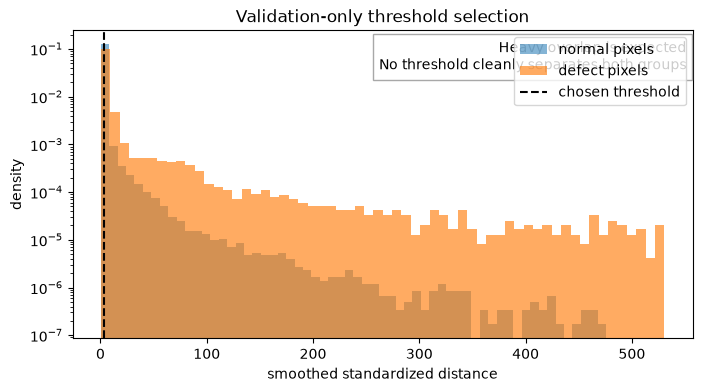

In [58]:
validation_pixels = np.concatenate([score.ravel() for score in threshold_score_maps])
validation_labels = np.concatenate([mask.ravel() for mask in threshold_masks])

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(
    validation_pixels[~validation_labels],
    bins=60,
    density=True,
    alpha=0.55,
    label="normal pixels",
)
ax.hist(
    validation_pixels[validation_labels],
    bins=60,
    density=True,
    alpha=0.65,
    label="defect pixels",
)
ax.axvline(selected_threshold, color="black", linestyle="--", label="chosen threshold")
ax.set(xlabel="smoothed standardized distance", ylabel="density",
       title="Validation-only threshold selection")
ax.set_yscale("log")
ax.legend()
ax.text(
    0.99,
    0.97,
    "Heavy overlap is expected\nNo threshold cleanly separates both groups",
    transform=ax.transAxes,
    ha="right",
    va="top",
    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "0.6"},
)
plt.show()

## 6. Freeze choices and report test results

The following metrics are the Task B results. Do not return to the validation
stage after inspecting them.


{'image_auroc': 0.6516183270281631, 'by_defect_type': {'color': {'f1': 0.31683168316831684, 'iou': 0.18823529411764706}, 'cut': {'f1': 0.06470374409305707, 'iou': 0.03343350864012021}, 'good': {'f1': 0.0, 'iou': 0.0}, 'hole': {'f1': 0.1260037059913527, 'iou': 0.06723796967699407}, 'metal_contamination': {'f1': 0.0, 'iou': 0.0}, 'thread': {'f1': 0.08158765159867695, 'iou': 0.04252873563218391}, 'bent': {'f1': 0.0, 'iou': 0.0}, 'broken': {'f1': 0.0, 'iou': 0.0}, 'glue': {'f1': 0.20161725067385444, 'iou': 0.11211031175059952}, 'fold': {'f1': 0.21352933848262115, 'iou': 0.1195258019525802}, 'poke': {'f1': 0.028629220476116383, 'iou': 0.01452249408050513}, 'crack': {'f1': 0.0, 'iou': 0.0}, 'glue_strip': {'f1': 0.0004822763443453099, 'iou': 0.000241196333815726}, 'gray_stroke': {'f1': 0.0, 'iou': 0.0}, 'oil': {'f1': 0.0, 'iou': 0.0}, 'rough': {'f1': 0.011301799916282964, 'iou': 0.005683014102294254}, 'combined': {'f1': 0.31197771587743733, 'iou': 0.1848184818481848}, 'liquid': {'f1': 0.46713

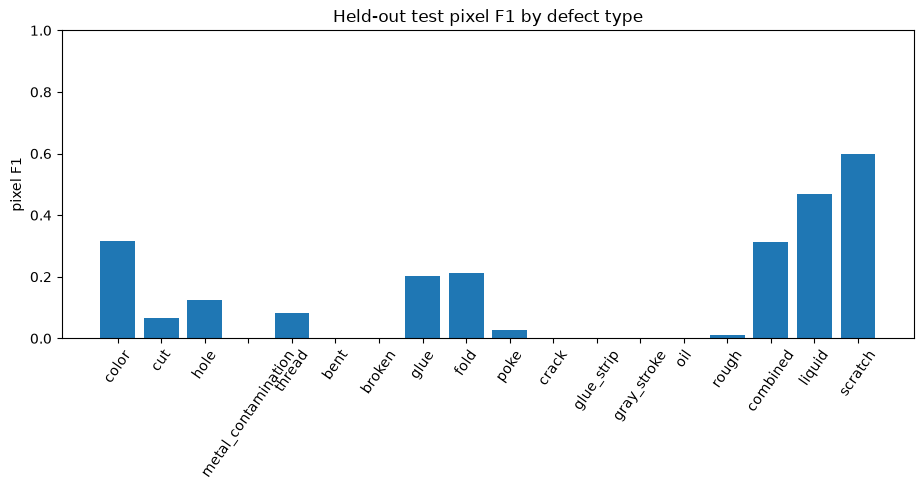

In [59]:
task_b_test = evaluation_subset("test")
test_score_maps, test_image_scores, test_predicted_masks, test_true_masks = score_dataset(
    task_b_test,
    feature_config,
    normal_models,
)
task_b_report = evaluate_detection(
    [record.defect_type != "good" for record in task_b_test],
    test_image_scores,
    test_true_masks,
    test_predicted_masks,
    [record.defect_type for record in task_b_test],
)
print(task_b_report)

# Summarise test behaviour by defect type.
defect_names = [name for name in task_b_report["by_defect_type"] if name != "good"]
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(
    defect_names,
    [task_b_report["by_defect_type"][name]["f1"] for name in defect_names],
)
ax.set(title="Held-out test pixel F1 by defect type", ylabel="pixel F1", ylim=(0, 1))
ax.tick_params(axis="x", rotation=55)
plt.show()

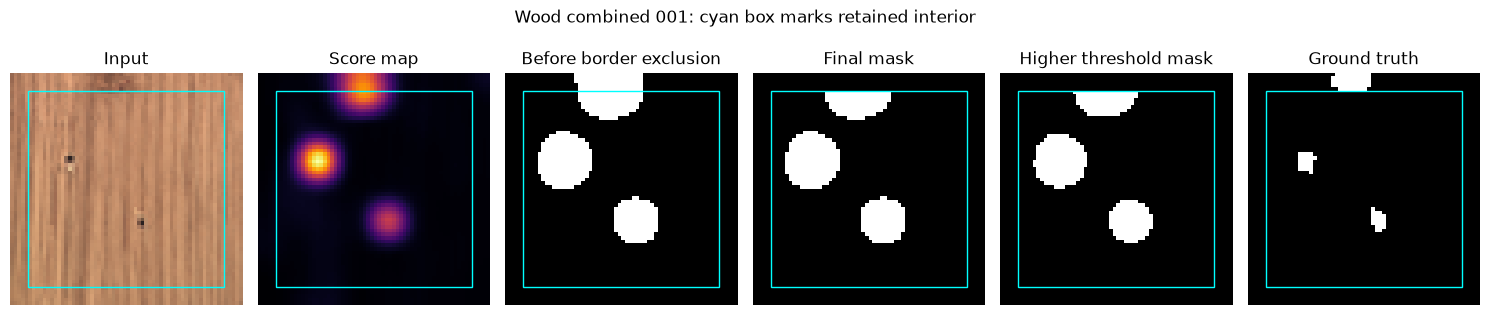

Before border exclusion: {'f1': 0.3008, 'iou': 0.17702448210922786}
After border exclusion:  {'f1': 0.16165413533834586, 'iou': 0.08793456032719836}
Threshold: 3.1952 → 3.8342
Original mask: {'f1': 0.16165413533834586, 'iou': 0.08793456032719836}
Higher-threshold mask: {'f1': 0.17842323651452283, 'iou': 0.0979498861047836}
Predicted pixels from original to higher threshold: 438 → 388
Image score at 99%: 17.5514
Image score at 99.9%: 22.4837


In [60]:
# proposal of visualizing the effect of border exclusion and threshold 
# selection on a single image. `[AI-DESIGN]` 

from matplotlib.patches import Rectangle
from texturelab.metrics import binary_pixel_metrics

index = next(
    i for i, record in enumerate(task_b_test)
    if record.material == "wood"
    and record.defect_type == "combined"
    and Path(record.path).name == "001.png"
)

record = task_b_test[index]
image = load_image(record.path, IMAGE_SIZE)
score = test_score_maps[index]
final_mask = test_predicted_masks[index]
truth = test_true_masks[index]

threshold = normal_models[record.material].threshold
before_border = score >= threshold

border = normal_config.ignore_border
height, width = score.shape

# Arbitrarily increase to show effect of higher threshold
higher_threshold = threshold * 1.20 
higher_mask = score >= higher_threshold

# Apply the same border exclusion.
if border > 0:
    higher_mask[:border, :] = False
    higher_mask[-border:, :] = False
    higher_mask[:, :border] = False
    higher_mask[:, -border:] = False

interior = score[border:-border, border:-border]

panels = [
    (image, "Input", None),
    (score, "Score map", "inferno"),
    (before_border, "Before border exclusion", "gray"),
    (final_mask, "Final mask", "gray"),
    (higher_mask, "Higher threshold mask", "gray"),
    (truth, "Ground truth", "gray"), 
]

fig, axes = plt.subplots(1, 6, figsize=(15, 3.4))

for ax, (data, title, cmap) in zip(axes, panels):
    ax.imshow(data, cmap=cmap)

    # Pixel centres have integer coordinates, so -0.5 aligns 
    # the rectangle with the edges of the retained pixels.
    ax.add_patch(Rectangle(
        (border - 0.5, border - 0.5),
        width - 2 * border,
        height - 2 * border,
        fill=False,
        edgecolor="cyan",
        linewidth=1,
    ))

    ax.set_title(title)
    ax.axis("off")

fig.suptitle(
    "Wood combined 001: cyan box marks retained interior"
)
fig.tight_layout()


plt.show()

before_metrics = binary_pixel_metrics(truth, before_border)
after_metrics = binary_pixel_metrics(truth, final_mask)

print("Before border exclusion:", before_metrics)
print("After border exclusion: ", after_metrics)

print(f"Threshold: {threshold:.4f} → {higher_threshold:.4f}")
print("Original mask:", binary_pixel_metrics(truth, final_mask))
print("Higher-threshold mask:", binary_pixel_metrics(truth, higher_mask))
print(f"Predicted pixels from original to higher threshold: {final_mask.sum()} → {higher_mask.sum()}")
print(f"Image score at 99%: {np.percentile(interior, 99):.4f}")
print(f"Image score at 99.9%: {np.percentile(interior, 99.9):.4f}")

### Inspect an easier colour defect and its patch scores

Colour defects are often more visible to this compact descriptor than small
structural defects. This example is illustrative: many MVTec samples will have
substantially weaker localization and should be discussed honestly.


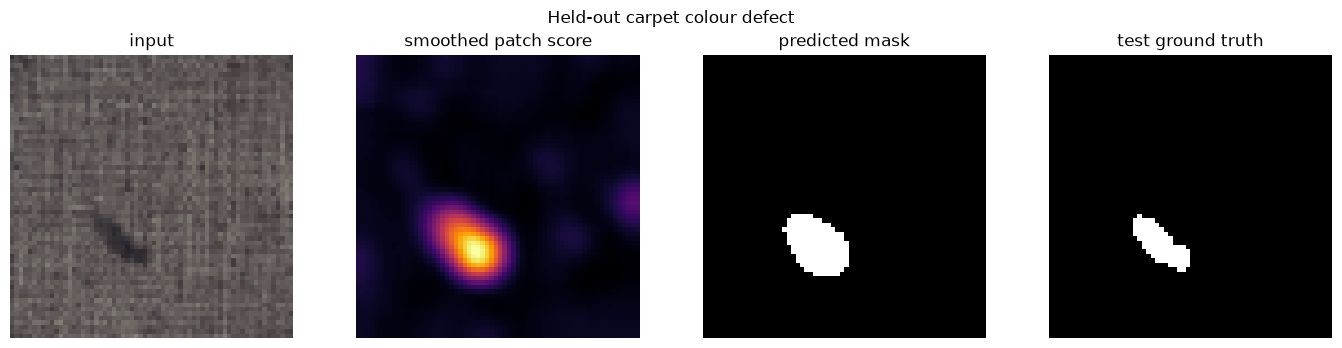

In [61]:
example_index = next(
    index
    for index, record in enumerate(task_b_test)
    if record.material == "carpet" and record.defect_type == "color"
)
example = task_b_test[example_index]
example_image = load_image(example.path, IMAGE_SIZE)
example_score = test_score_maps[example_index]
example_prediction = test_predicted_masks[example_index]
example_truth = test_true_masks[example_index]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
panels = [
    (example_image, "input", None),
    (example_score, "smoothed patch score", "inferno"),
    (example_prediction, "predicted mask", "gray"),
    (example_truth, "test ground truth", "gray"),
]
for ax, (data, title, cmap) in zip(axes, panels):
    ax.imshow(data, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
fig.suptitle("Held-out carpet colour defect")
fig.tight_layout()
plt.show()

## 7. Required feature-family ablation

Repeat the validation-threshold/test-report sequence for Gabor-only, edge-only,
and combined configurations. Do not share a threshold between branches unless
you justify doing so, and do not choose the winning branch from test results.


In [62]:
ablation_configs = {
    "Gabor only": FeatureConfig(
        include_colour=False,
        include_gradient=False,
        include_edges=False,
        gabor=feature_config.gabor,
    ),
    "Edge only": FeatureConfig(
        include_colour=False,
        include_gabor=False,
        gabor=feature_config.gabor,
    ),
    "Combined": feature_config,
}

print("Configurations prepared:", list(ablation_configs))

Configurations prepared: ['Gabor only', 'Edge only', 'Combined']


Gabor only: threshold=4.8237
{'image_auroc': 0.6944934846574191, 'by_defect_type': {'color': {'f1': 0.29553378714926115, 'iou': 0.17338788233002142}, 'cut': {'f1': 0.06218340611353712, 'iou': 0.032089417703263026}, 'good': {'f1': 0.0, 'iou': 0.0}, 'hole': {'f1': 0.1238725195429946, 'iou': 0.06602564102564103}, 'metal_contamination': {'f1': 0.0, 'iou': 0.0}, 'thread': {'f1': 0.07939914163090128, 'iou': 0.041340782122905026}, 'bent': {'f1': 0.0, 'iou': 0.0}, 'broken': {'f1': 0.0, 'iou': 0.0}, 'glue': {'f1': 0.1955044432828019, 'iou': 0.10834298957126304}, 'fold': {'f1': 0.20236127508854782, 'iou': 0.11257060291606463}, 'poke': {'f1': 0.02699530516431925, 'iou': 0.013682331945270671}, 'crack': {'f1': 0.0, 'iou': 0.0}, 'glue_strip': {'f1': 0.004804227720393947, 'iou': 0.0024078979051288226}, 'gray_stroke': {'f1': 0.0, 'iou': 0.0}, 'oil': {'f1': 0.0, 'iou': 0.0}, 'rough': {'f1': 0.059135399673735725, 'iou': 0.03046858583736079}, 'combined': {'f1': 0.30535510824154954, 'iou': 0.1801882563872

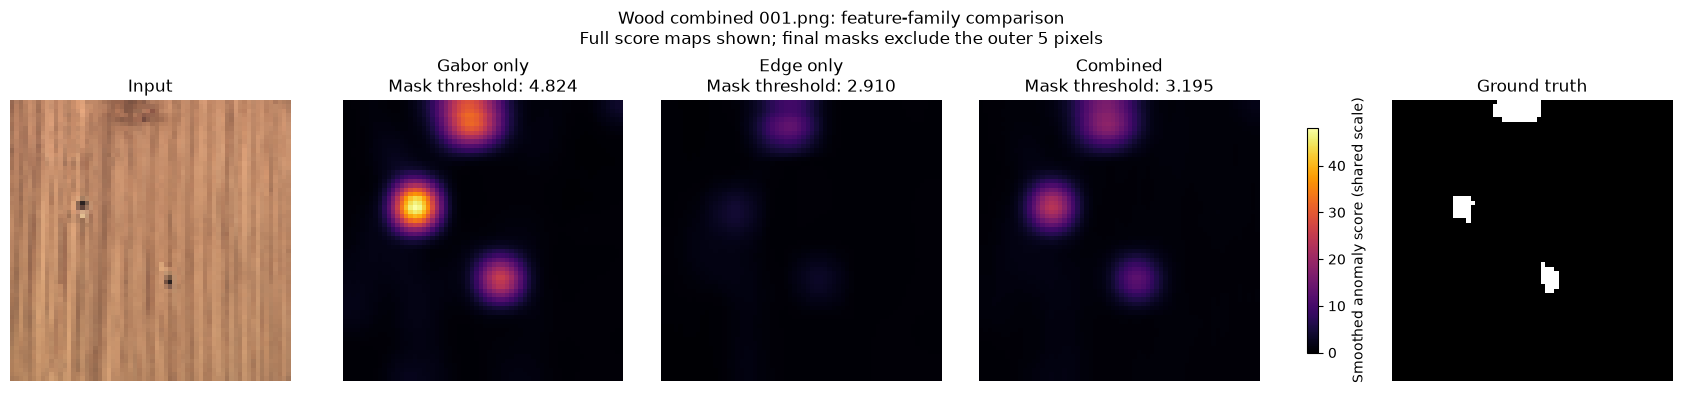

In [63]:
# YOUR CODE HERE
#
# TODO repeat the validation-to-test workflow for each configuration in ablation_configs

ablation_reports = {}
ablation_example_maps = {}

ablation_test_records = evaluation_subset("test")
ablation_example_index = next(
    i for i, record in enumerate(ablation_test_records)
    if record.material == "wood"
    and record.defect_type == "combined"
    and Path(record.path).name == "001.png"
)
ablation_example = ablation_test_records[ablation_example_index]

for name, config in ablation_configs.items():

    models = {}
    for material in MATERIALS:
        records = [
            record
            for record in mvtec
            if record.split == "train" and record.material == material
        ]

        feature_maps = [
            extract_local_features(
                load_image(record.path, IMAGE_SIZE),
                config,
            )[0]
            for record in records
        ]

        models[material] = fit_normal_model(feature_maps, normal_config)

    ablation_validation_records = evaluation_subset("validation")
    validation_score_maps, _, _, validation_masks = score_dataset(
        ablation_validation_records,
        config,
        models,
    )

    threshold_score_maps = validation_score_maps
    threshold_masks = validation_masks

    if normal_config.ignore_border:
        border = normal_config.ignore_border
        threshold_score_maps = [
            score[border:-border, border:-border]
            for score in validation_score_maps
        ]
        threshold_masks = [
            mask[border:-border, border:-border]
            for mask in validation_masks
        ]

    selected_ablation_threshold = select_mask_threshold(
        threshold_score_maps,
        threshold_masks,
    )

    for model in models.values():
        model.threshold = selected_ablation_threshold

    ablation_score_maps, test_image_scores, test_predicted_masks, test_true_masks = score_dataset(
        ablation_test_records,
        config,
        models,
    )

    test_report = evaluate_detection(
        [record.defect_type != "good" for record in ablation_test_records],
        test_image_scores,
        test_true_masks,
        test_predicted_masks,
        [record.defect_type for record in ablation_test_records],
    )

    ablation_reports[name] = {
        "validation_threshold": selected_ablation_threshold,
        "test_report": test_report,
    }
    ablation_example_maps[name] = ablation_score_maps[ablation_example_index]

    print(f"{name}: threshold={selected_ablation_threshold:.4f}")
    print(test_report)

# Compare dense anomaly scores, using identical colour limits in every panel.
ablation_image = load_image(ablation_example.path, IMAGE_SIZE)
ablation_truth = load_mask(ablation_example.mask_path, IMAGE_SIZE)
score_max = max(float(score.max()) for score in ablation_example_maps.values())
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8), constrained_layout=True)
axes[0].imshow(ablation_image)
axes[0].set_title("Input")

for ax, (name, score) in zip(axes[1:4], ablation_example_maps.items()):
    heatmap = ax.imshow(score, cmap="inferno", vmin=0, vmax=score_max)
    threshold = ablation_reports[name]["validation_threshold"]
    ax.set_title(f"{name}\nMask threshold: {threshold:.3f}")

axes[4].imshow(ablation_truth, cmap="gray", vmin=0, vmax=1)
axes[4].set_title("Ground truth")
for ax in axes:
    ax.axis("off")
fig.colorbar(
    heatmap, ax=list(axes[1:4]), shrink=0.8,
    label="Smoothed anomaly score (shared scale)",
)
fig.suptitle(
    f"Wood combined {Path(ablation_example.path).name}: feature-family comparison\n"
    f"Full score maps shown; final masks exclude the outer {normal_config.ignore_border} pixels"
)
plt.show()

In [64]:
# Save the frozen Task A/B artifacts for Notebook 4.
MODEL_DIR = ROOT / "outputs" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
task_ab_model_path = MODEL_DIR / "task_ab_models.joblib"
joblib.dump(
    {
        "material_classifier": material_model,
        "normal_models": normal_models,
        "feature_config": feature_config,
        "normality_config": normal_config,
        "materials": MATERIALS,
        "image_size": IMAGE_SIZE,
        "validation_selected_threshold": selected_threshold,
    },
    task_ab_model_path,
)
print("Saved frozen Task A/B models to:", task_ab_model_path)

Saved frozen Task A/B models to: c:\Users\Matthew\Desktop\Y4S1\CS4243 Lab 1\code\outputs\models\task_ab_models.joblib
